In [1]:
from dataset import MVTec3D_RGB_Dataset, MVTec2DDataset
from models.pixel_autoencoder import Autoencoder
from utils.helpers import set_seed, get_device
from visualization import visualize_batch
from utils.data_split import split_data
from torchvision.transforms import v2
from torchinfo import summary
from engine import train
import torch.nn as nn
import torch

W1106 14:34:36.749000 24612 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


In [2]:
config = {

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,

    # dataset
    'img_size': (256, 256),
    'batch_size': 16,

    # model
    'base_channels': 16,
    'num_epochs': 2,
    'class_name': 'bottle',  # Specify the class name for training and evaluation
}

In [3]:
set_seed(42)
DEVICE = get_device()

Random seed set to 42.
Using device: cuda.


### Dataset and DataLoaders

In [4]:
do_split = False  # Set to True if you want to split the dataset into training and validation sets
if do_split:
    # Split a single class
    #split_data(root="./data/MVTec", class_name="bottle", val_ratio=0.15)

    # Or split all classes under data/MVTec at once:
    split_data(root="./data/MVTec", val_ratio=0.15)

In [5]:
transforms = v2.Compose([
    v2.Resize(config['img_size']),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),  # valori in [0, 1]
])


# transforms = v2.Compose([
#     v2.Resize(config["img_size"]),

#     v2.RandomHorizontalFlip(p=0.5),
#     v2.RandomVerticalFlip(p=0.5),

#     v2.RandomApply([
#         v2.RandomRotation(degrees=10)
#     ], p=0.3),

#     v2.RandomApply([
#         v2.ColorJitter(
#             brightness=0.15,
#             contrast=0.15,
#             saturation=0.1,
#             hue=0.02
#         )
#     ], p=0.3),

#     v2.ToImage(),
#     v2.ToDtype(torch.float32, scale=True),

#     v2.RandomErasing(
#         p=0.4,
#         scale=(0.02, 0.12),
#         ratio=(0.3, 3.3),
#         value=0
#     ),
# ])

test_transforms = v2.Compose([
    v2.Resize(config["img_size"]),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

train_dataset = MVTec2DDataset(
    transforms=transforms,
    class_name=config['class_name'],
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=config['batch_size'],
    shuffle=True,
    num_workers=config['num_workers'],
    pin_memory=True,
)

val_dataset = MVTec2DDataset(
    transforms=transforms,
    split='validation',
    class_name=config['class_name']
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config['num_workers'],
    pin_memory=True,
)

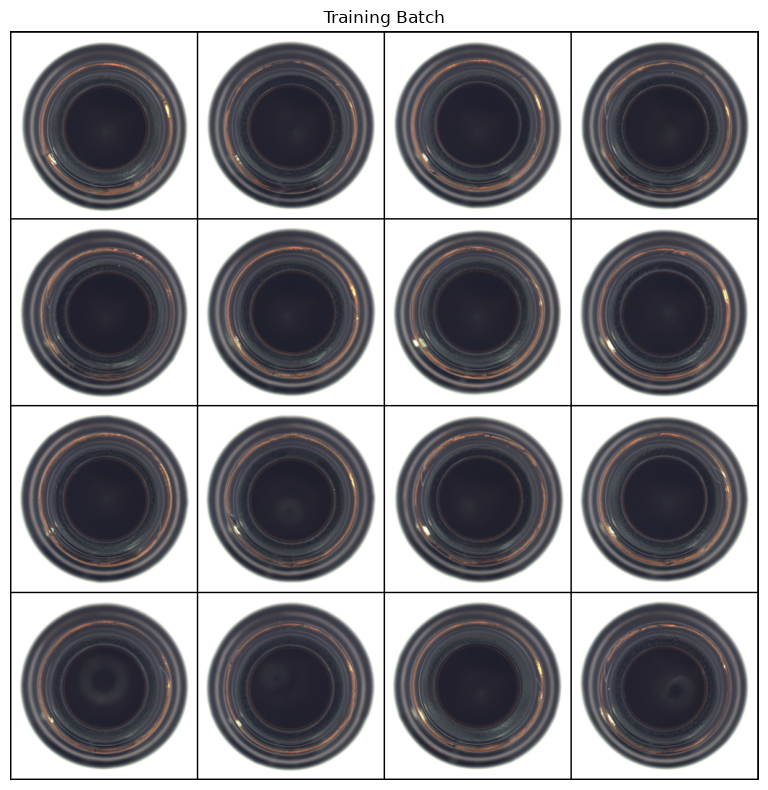

In [6]:
# visualize a batch of images
visualize_batch(train_loader)

### Model Instantiation and training

Input images shape: torch.Size([16, 3, 256, 256])
Reconstructed images shape: torch.Size([16, 3, 256, 256])


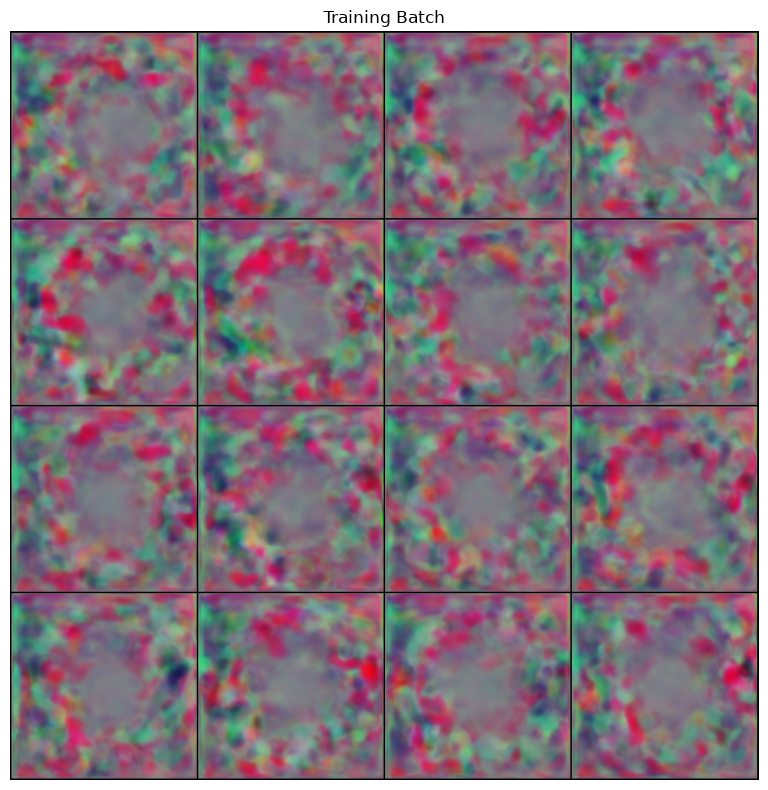

In [7]:
from models.pixel_autoencoder import ResAutoencoder
#model = ResAutoencoder(in_channels=3, base_channels=config['base_channels'], bottleneck_type='attention').to(DEVICE)
model = Autoencoder(in_channels=3, base_channels=config['base_channels']).to(DEVICE)
# single forward pass to check if the model works
sample_batch = next(iter(train_loader))
with torch.no_grad():
    sample_images = sample_batch['image'].to(DEVICE)
    reconstructed_images, _ = model(sample_images)

print(f"Input images shape: {sample_images.shape}")
print(f"Reconstructed images shape: {reconstructed_images.shape}")
visualize_batch(reconstructed_images)

In [8]:
print(summary(model, input_size=(config['batch_size'], 3, *config['img_size']), device=DEVICE))

Layer (type:depth-idx)                   Output Shape              Param #
Autoencoder                              [16, 3, 256, 256]         --
├─Sequential: 1-1                        [16, 128, 16, 16]         --
│    └─EncoderBlock: 2-1                 [16, 16, 128, 128]        --
│    │    └─Sequential: 3-1              [16, 16, 128, 128]        2,832
│    └─EncoderBlock: 2-2                 [16, 32, 64, 64]          --
│    │    └─Sequential: 3-2              [16, 32, 64, 64]          14,016
│    └─EncoderBlock: 2-3                 [16, 64, 32, 32]          --
│    │    └─Sequential: 3-3              [16, 64, 32, 32]          55,680
│    └─EncoderBlock: 2-4                 [16, 128, 16, 16]         --
│    │    └─Sequential: 3-4              [16, 128, 16, 16]         221,952
├─Sequential: 1-2                        [16, 3, 256, 256]         --
│    └─DecoderBlock: 2-5                 [16, 64, 32, 32]          --
│    │    └─Sequential: 3-5              [16, 64, 32, 32]          73

In [9]:
#criterion = nn.MSELoss()
from losses import L1SSIMLoss
# Invece di criterion = nn.MSELoss()
criterion = L1SSIMLoss(alpha=0.5)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history = train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=config['num_epochs'],
    device=DEVICE,
    save_dir="./experiments/pixel_reconstruction",
)

Epoch [001/002] | Train Loss: 0.06294 | Val Loss: 0.16637


Epoch [002/002] | Train Loss: 0.01123 | Val Loss: 0.03596


In [10]:
continue_training = False  # Set to True if you want to continue training from a saved checkpoint
if continue_training:
    history = train(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=optimizer,
        epochs=30,
        device=DEVICE,
        save_dir="./experiments/baseline",
    )

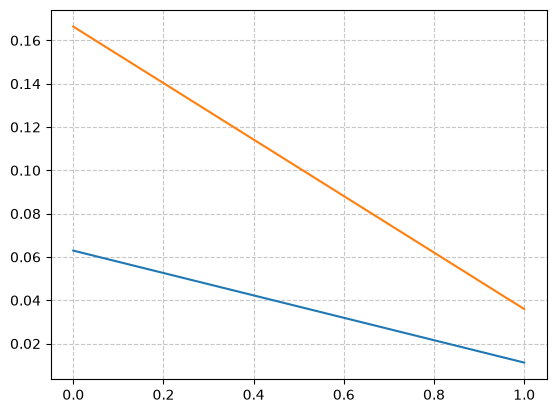

In [11]:
import matplotlib.pyplot as plt

plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.grid(linestyle='--', alpha=0.7)

In [12]:
target_transforms = v2.Compose([
    v2.Resize(config['img_size'], interpolation=v2.InterpolationMode.NEAREST),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

# test dataset
test_dataset = MVTec2DDataset(
    transforms=transforms,
    target_transforms=target_transforms,
    split='test',
    class_name=config['class_name']
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=config['batch_size'],
    shuffle=True,
    num_workers=config['num_workers'],
    pin_memory=True,
)

# single batch forward pass on test set
# batch = next(iter(test_loader))
# with torch.no_grad():
#     test_images = batch['image'].to(DEVICE)
#     reconstructed_test_images = model(test_images)

# # visualize a batch of test images and their reconstructions
# visualize_batch(test_images)

# # visualize a batch of reconstructed test images
# visualize_batch(reconstructed_test_images)



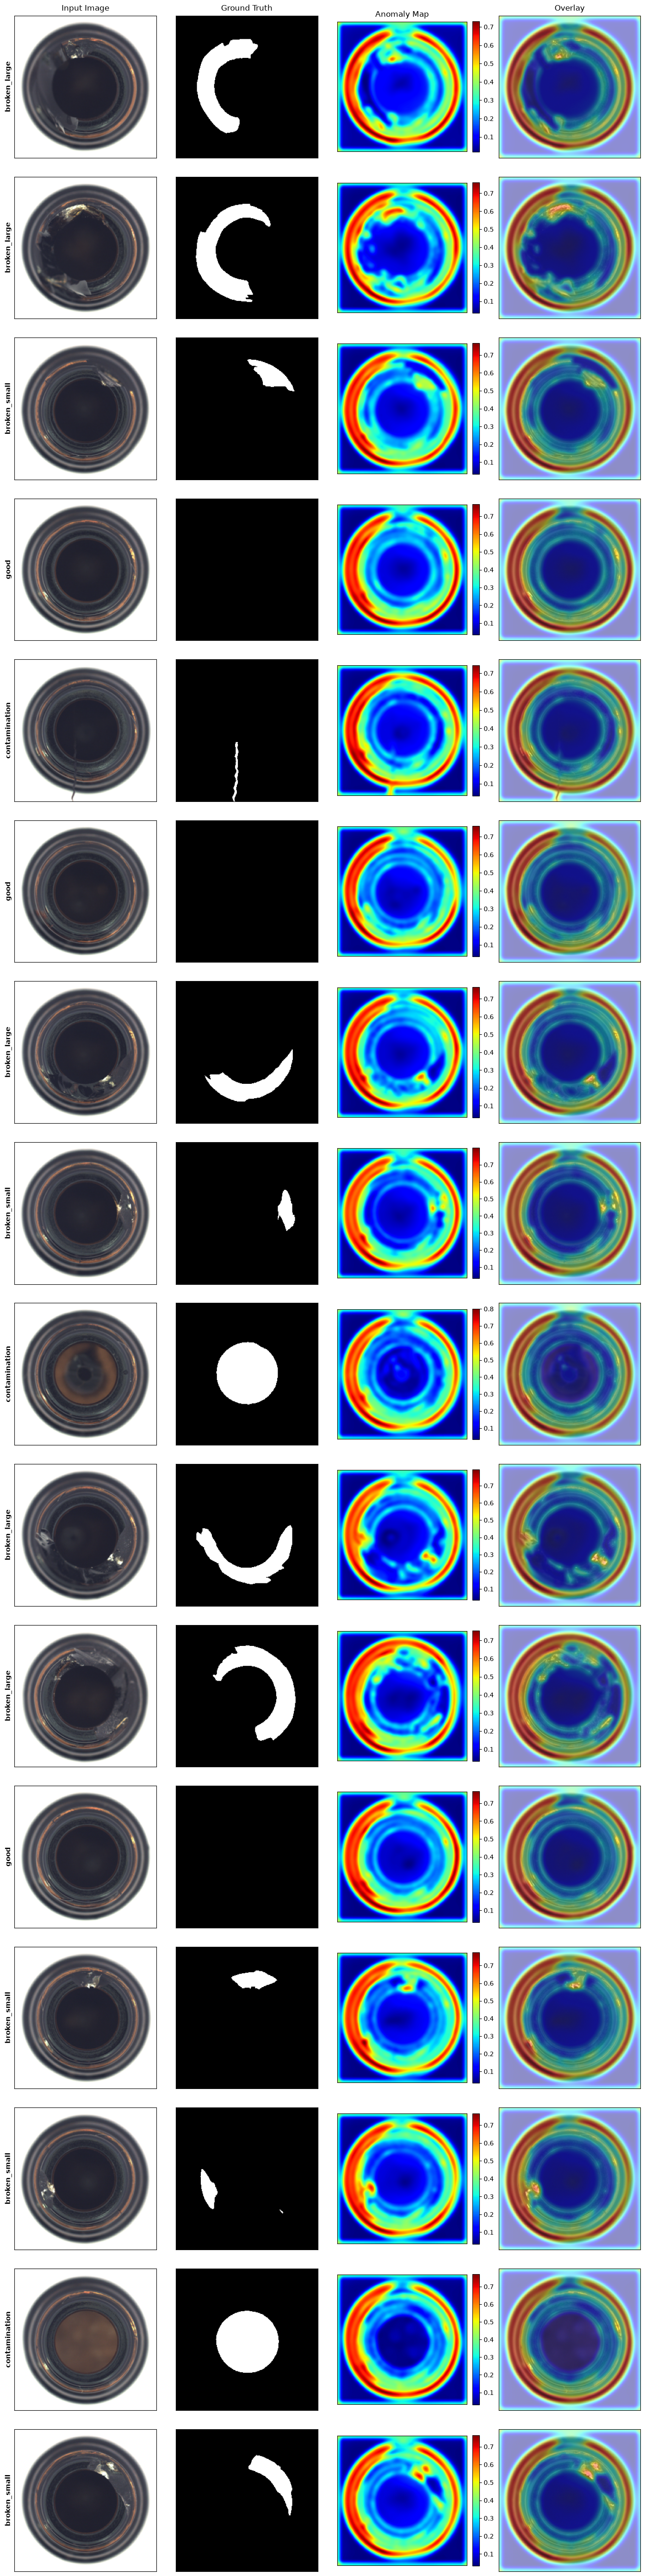

In [13]:
from engine import evaluate
from visualization import visualize_anomalies


# 2. Run quantitative evaluation (Image & Pixel AUROC)
metrics = evaluate(model, test_loader, DEVICE)

# 3. Visualize qualitative anomaly heatmaps
visualize_anomalies(model, test_loader, DEVICE, num_samples=16)

In [15]:
for key, value in metrics.items():
    print(f"{key}: {value}")

image_auroc: 0.33095240592956543
pixel_auroc: 0.4382496476173401
aupro: 0.1318904161453247
